# MapTheMap — Image Stitching Pipeline
Stitches fragmented aerial/satellite images into seamless 2D maps using feature-based matching, community detection, and homography warping.

In [51]:
# Basic Imports
import os
import numpy as np
import math
import matplotlib.pyplot as plt
# Grouping + Stitching imports
import cv2
import networkx as nx
from networkx.algorithms import community
from itertools import combinations

In [52]:
# Load Dataset

def load_images(class_folder, img_size=(64, 64)):
    X = []
    VALID_EXT = {'.jpg', '.jpeg', '.png', '.tif', '.tiff'}

    for file in os.listdir(class_folder):
        if os.path.splitext(file)[1].lower() not in VALID_EXT:
            continue
        img_path = os.path.join(class_folder, file)

        # Read image (BGR)
        img = cv2.imread(img_path) 

        if img is None:
            continue  # skip corrupted files
        
        X.append(img)

    return X

In [53]:
X_train = load_images("Datasets/test_s_imgs/a_3")

### Phase 1: Feature Extraction & Grouping
- Extracts SIFT keypoints from each image
- Matches them pairwise using BFMatcher + RANSAC
- Groups images into coherent regions using community detection on the similarity graph

In [54]:
# Extract local features from every image - SIFT

sift = cv2.SIFT_create()
orb = cv2.ORB_create(nfeatures=2000)

def extract_features(images):
    features = []

    for img in images:

        kp, des = sift.detectAndCompute(img, None)
        if des is None or len(kp) < 20:
            kp, des = orb.detectAndCompute(img, None)
            
        features.append((kp, des))
    
        SHOW_KEYPOINTS = False  # True -> if you want to display keypoints extracted

        if SHOW_KEYPOINTS:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) 
            img2 = cv2.drawKeypoints(img_rgb, kp, None, color=(255,0,255), flags=0)
            plt.imshow(img2), plt.show()

    return features

In [55]:
#  Computes what fraction of img1 is covered by the projected img2.

def compute_overlap_ratio(H, img_shape):
    h, w = img_shape[:2]
    corners = np.float32([[0,0],[w,0],[w,h],[0,h]]).reshape(-1,1,2)
    projected = cv2.perspectiveTransform(corners, H)
    
    rect1 = (0, 0, w, h)
    x,y,w2,h2 = cv2.boundingRect(projected.astype(np.int32))
    
    ix = max(0, min(rect1[2], x+w2) - max(rect1[0], x))
    iy = max(0, min(rect1[3], y+h2) - max(rect1[1], y))
    intersection = ix * iy
    
    return intersection / (w * h)  

In [ ]:
def build_similarity_graph(features, images, ratio_threshold=0.65, min_inliers=150):
    G = nx.Graph()

    total_matches = 0
    for i, j in combinations(range(len(images)), 2):
        img1, (kp1, des1) = images[i], features[i]
        img2, (kp2, des2) = images[j], features[j]

        # Skip if one image has no descriptors
        if des1 is None or des2 is None:
            continue

        if des1.dtype == np.uint8:
            bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)
        else:
            bf = cv2.BFMatcher(cv2.NORM_L2, crossCheck=False)

        if des1.dtype != des2.dtype:
            continue  # skip incompatible descriptor types

        # Use knnMatch to find the two best matches for each descriptor
        matches = bf.knnMatch(des1, des2, k=2)  

        # Apply Lowe's Ratio Test to filter out ambiguous matches
        filtered_matches = []
        for pair in matches:
            if len(pair) < 2:
                continue  # skip incomplete matches
            m, n = pair
            if m.distance < ratio_threshold * n.distance:
                filtered_matches.append(m)

        if len(filtered_matches) < 4: # Min 4 points needed for homography
            continue

        # Geometric Verification using RANSAC
        src_pts = np.float32([kp1[m.queryIdx].pt for m in filtered_matches]).reshape(-1,1,2)
        dest_pts = np.float32([kp2[m.trainIdx].pt for m in filtered_matches]).reshape(-1,1,2)

        H, mask = cv2.findHomography(src_pts, dest_pts, cv2.RANSAC, ransacReprojThreshold=3.0)

        if H is None:
            continue

        inliers = int(mask.sum()) # number of geometrically consistent matches

        # Build Graph Edge if enough matches
        overlap = compute_overlap_ratio(H, images[i].shape)
        
        if inliers >= min_inliers and overlap > 0.1:  # at least 10% overlap
            G.add_edge(i, j, weight=inliers, overlap=overlap, H=H, src=i, dst=j)
        
        total_matches += inliers
    
    print("Total matches: ",total_matches)
    print("Number of edges (similar pairs):", G.number_of_edges())

    return G

In [57]:
def display_graphs(graph):
        # Display edge weight distribution
        weights = [d['weight'] for u, v, d in graph.edges(data=True)]
        if len(weights) > 0:
                plt.hist(weights, bins=20)
                print(f"Min: {min(weights)}, Max: {max(weights)}, Mean: {np.mean(weights):.1f}")
                plt.xlabel("RANSAC Inlier Count")
                plt.ylabel("Number of Pairs")
                plt.title("Edge Weight Distribution")
                plt.show()
        else:
                print("No edges found")

        # Display simililarity graph (NetworkX)
        nx.draw(graph,
                pos=nx.circular_layout(graph),
                with_labels=True,
                node_color='violet', 
                edge_color='gray')
        plt.show()

Total matches:  10508
Number of edges (similar pairs): 53
Min: 25, Max: 664, Mean: 184.8


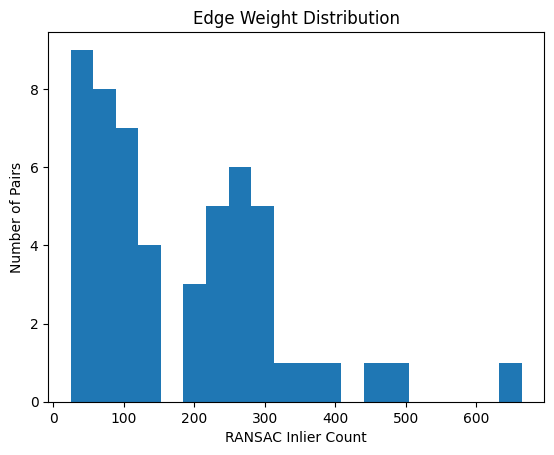

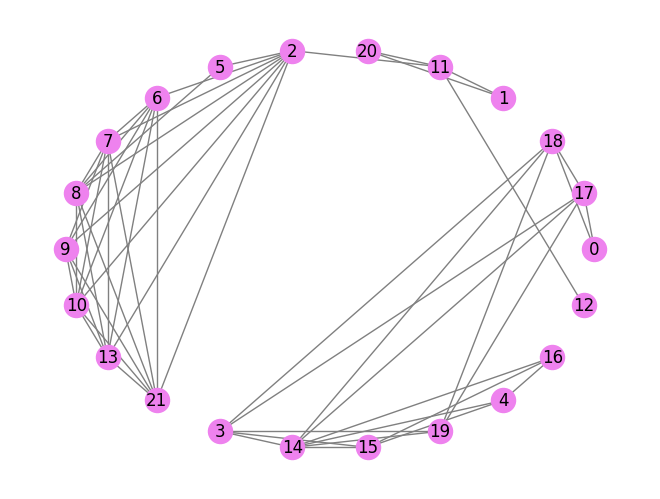

In [58]:
# Extracting features and building similarity graph for regional grouping

features = extract_features(X_train)
graph = build_similarity_graph(features, X_train, min_inliers=20)
display_graphs(graph)

In [59]:
# Louvain-style community detection (greedy modularity) -> performs better than component detection 

communities = community.greedy_modularity_communities(graph, weight='weight')
for idx, comp in enumerate(communities):
    print(f"Group {idx}: images {sorted(comp)}")

Group 0: images [2, 5, 6, 7, 8, 9, 10, 13, 21]
Group 1: images [0, 3, 4, 14, 15, 16, 17, 18, 19]
Group 2: images [1, 11, 12, 20]


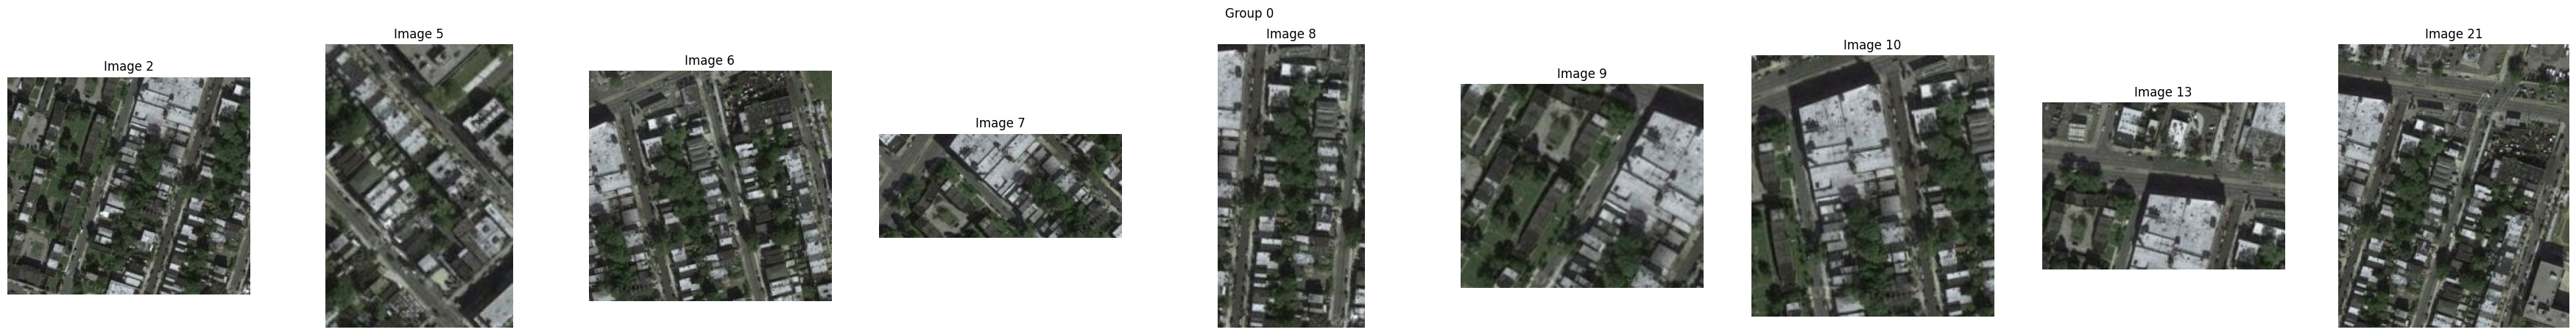

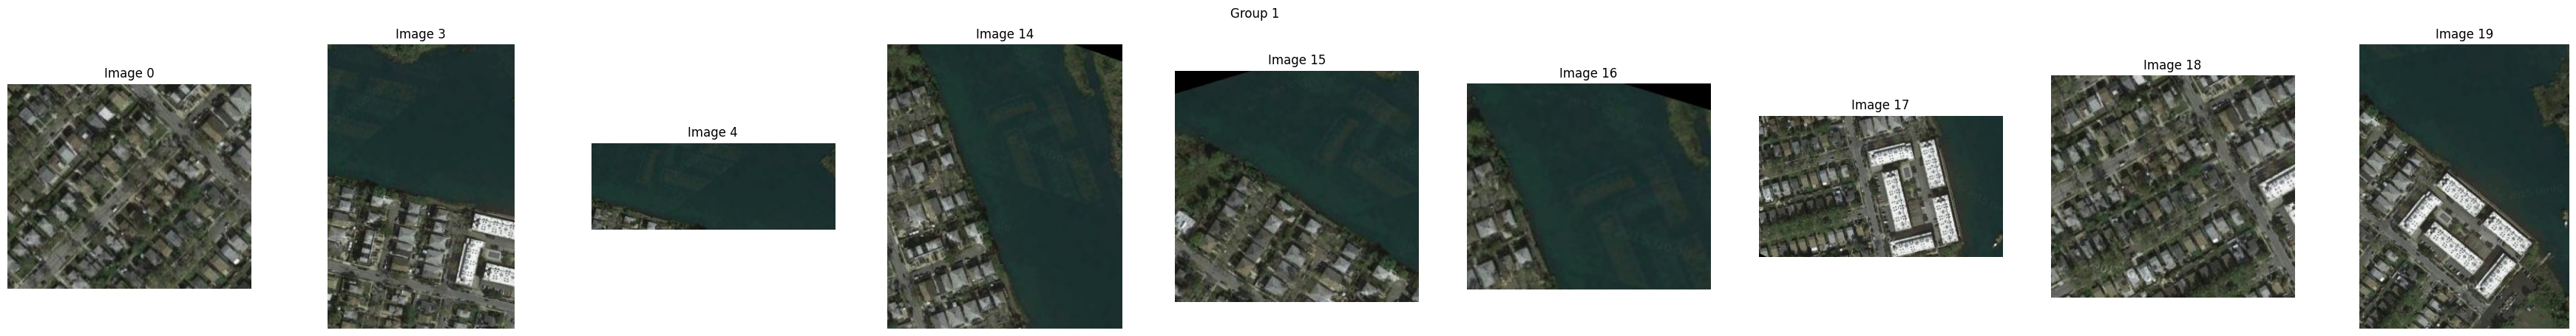

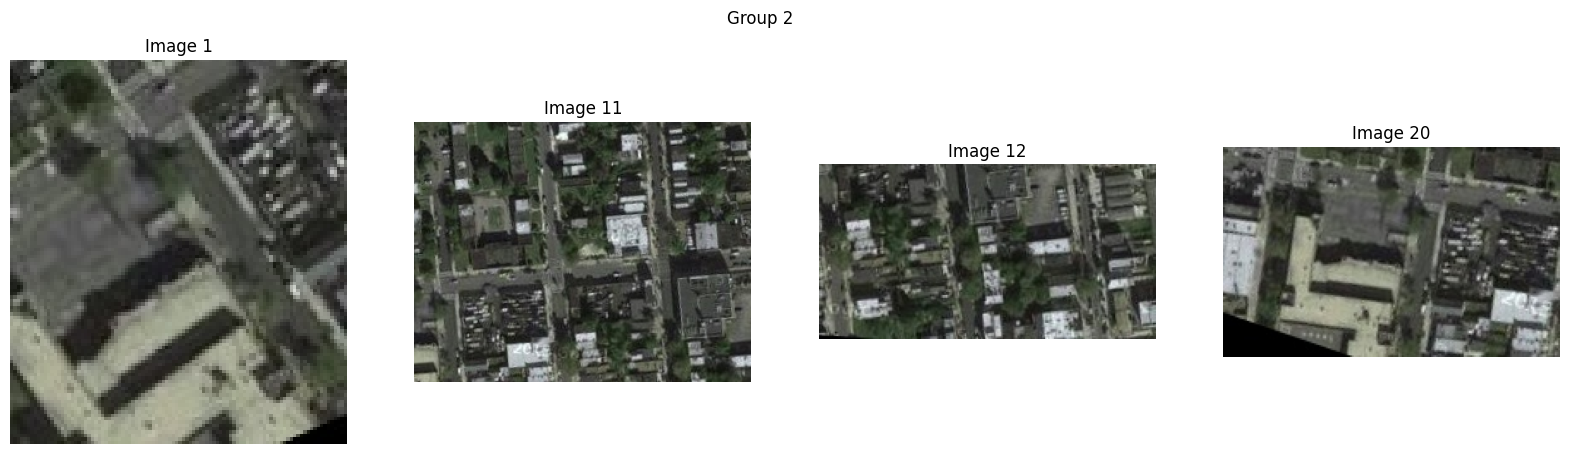

In [60]:
# Visualization of Community images

for group_idx, comp in enumerate(communities):
    images_in_group = sorted(comp)
    n = len(images_in_group)
    fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
    if n == 1:
        axes = [axes]
    for ax, img_idx in zip(axes, images_in_group):
        ax.imshow(cv2.cvtColor(X_train[img_idx], cv2.COLOR_BGR2RGB))
        ax.set_title(f"Image {img_idx}")
        ax.axis('off')
    plt.suptitle(f"Group {group_idx}")
    plt.show()

### Phase 2: Image Stitching

Two-pass stitching pipeline run twice (regional → global):
- **Stitching Order** — MST + BFS from most connected reference node
- **Homography Chaining** — cumulative H maps each image directly to reference frame
- **Global Canvas Pre-computation** — canvas sized upfront via corner projection to eliminate drift
- **Feather Blending** — distance-transform weights for seamless overlap transitions

In [61]:
# Decide order for stitching on the basis of Maximum Spanning Tree (MaxST)

def compute_stitching_order(graph, communities):
    stitching_order = [None] * len(communities)
    bfs_trees = [None] * len(communities)
    reference_nodes = [None] * len(communities)

    for group_idx, comp in enumerate(communities):
        nodes = sorted(comp)
        subgraph = graph.subgraph(nodes)
        
        mst = nx.maximum_spanning_tree(subgraph, weight='weight')
        
        # Pick the node with highest degree in MST as reference (most central or has most connecting edges)
        reference = max(mst.nodes(), key=lambda n: mst.degree(n))
        reference_nodes[group_idx] = reference
        print(f"Group {group_idx}: nodes={nodes}, reference image={reference}")
        
        # BFS order from reference = stitching order
        bfs_trees[group_idx] = nx.bfs_tree(mst, reference)
        stitching_order[group_idx] = list(bfs_trees[group_idx].nodes())
        print(f"  Stitching order: {stitching_order[group_idx]}")
        print(bfs_trees[group_idx])
        print()

    return stitching_order, bfs_trees, reference_nodes

In [62]:
def compute_homographies(graph, bfs_trees, reference_nodes, Communities):
    H_cumulative = {}

    for group_idx, comp in enumerate(Communities):
        ref_node = reference_nodes[group_idx]
        
        for current_node in bfs_trees[group_idx]:
            if current_node == ref_node:
                H_cumulative[ref_node] = np.eye(3)
            else:
                prev_node = next(bfs_trees[group_idx].predecessors(current_node))
                
                # Get the homography that maps current_node -> prev_node's space
                if graph.has_edge(prev_node, current_node):
                    H_pair = np.linalg.inv(graph[prev_node][current_node]['H'])
                elif graph.has_edge(current_node, prev_node):
                    H_pair = graph[current_node][prev_node]['H']
                else:
                    print(f"Warning: No edge between {prev_node} and {current_node}")
                    H_cumulative[current_node] = H_cumulative[prev_node]
                    continue
                edge_data = graph[prev_node][current_node] if graph.has_edge(prev_node, current_node) \
                else graph[current_node][prev_node]
                
                H_raw = edge_data['H']
                src, dst = edge_data['src'], edge_data['dst']

                if src == prev_node:
                    H_pair = np.linalg.inv(H_raw)  # H maps prev->current, invert to get current->prev
                else:
                    H_pair = H_raw  # H maps current->prev, already correct

                H_new = H_cumulative[prev_node] @ H_pair

                # Reject unstable transforms
                if not np.isfinite(H_new).all() or np.linalg.norm(H_new) > 1e5:
                    print(f"Skipping unstable homography for node {current_node}")
                    H_cumulative[current_node] = H_cumulative[prev_node]
                else:
                    H_cumulative[current_node] = H_new

    return H_cumulative

In [ ]:
# Global canvas pre-computation

def calculate_canvas_size(nodes, images, H_cumulative):

    x_min_global, y_min_global = 0, 0
    x_max_global, y_max_global = 0, 0

    for node in nodes:
        h1, w1 = images[node].shape[:2]
        corners = np.float32([[0,0],[w1,0],[w1,h1],[0,h1]]).reshape(-1,1,2)
        warped_corners = cv2.perspectiveTransform(corners, H_cumulative[node])

        x_min, y_min = warped_corners[:,:,0].min(), warped_corners[:,:,1].min()
        x_max, y_max = warped_corners[:,:,0].max(), warped_corners[:,:,1].max()

        x_min_global = min(x_min_global, x_min)
        y_min_global = min(y_min_global, y_min)
        x_max_global = max(x_max_global, x_max)
        y_max_global = max(y_max_global, y_max)

    T_global = np.array([[1, 0, -x_min_global],
                        [0, 1, -y_min_global],
                        [0, 0,  1    ]])
    canvas_size = (int(x_max_global - x_min_global), int(y_max_global - y_min_global))

    canvas_w = int(x_max_global - x_min_global)
    canvas_h = int(y_max_global - y_min_global)

    # Limit size to prevent explosion
    MAX_SIZE = 5000

    if canvas_w <= 0 or canvas_h <= 0 or canvas_w > MAX_SIZE or canvas_h > MAX_SIZE:
        return np.eye(3), (1000, 1000)  # Fallback
    
    return T_global, canvas_size

In [64]:
# Warp image onto canvas

def warp_and_blend(img, H, T_cumulative, canvas_size):
    if H is None or not np.isfinite(H).all():
        return np.zeros((canvas_size[1], canvas_size[0], 3), dtype=np.uint8)

    # Normalize H to avoid extreme scaling
    if abs(H[2,2]) > 1e-8:
        H = H / H[2,2]

    H_total = T_cumulative @ H

    # Reject crazy transforms
    if np.linalg.norm(H_total) > 1e4:
        return np.zeros((canvas_size[1], canvas_size[0], 3), dtype=np.uint8)

    warped = cv2.warpPerspective(img, H_total, canvas_size)

    return warped

In [65]:
# Applies group-wise warping and feather blending

def stitch_images(bfs_trees, images, H_cumulative, Communities,feather_blending = True):
    T_cumulative = [None] * len(Communities)
    stitched_maps = [None] * len(Communities)
    canvas_size = [None] * len(Communities)
    canvas = [None] * len(Communities)

    # Calculate Cumulative Transformation for each group
    for group_idx, comp in enumerate(Communities):
                T_cumulative[group_idx], canvas_size[group_idx] = calculate_canvas_size(bfs_trees[group_idx], images, H_cumulative)
                canvas[group_idx] = np.zeros((canvas_size[group_idx][1], canvas_size[group_idx][0], 3), dtype=np.uint8)

    # Warp and blend images region wise
    for group_idx, comp in enumerate(Communities):
        cumulative_weight = np.zeros(canvas_size[group_idx][::-1], dtype=np.float32)
        for current_node in bfs_trees[group_idx]:
                warped = warp_and_blend(images[current_node], H_cumulative[current_node], T_cumulative[group_idx], canvas_size[group_idx])
                mask = warped.any(axis=2) # non-black pixels
                if feather_blending:
                    mask_float = mask.astype(np.uint8)  
                    mask_weight = cv2.distanceTransform(mask_float, cv2.DIST_L2, 5)

                    mw = mask_weight[:,:,np.newaxis] # Conversion to 3D for computing with 3D image arrays
                    cumw = cumulative_weight[:,:,np.newaxis] # And 2D when working with 2D masks

                    new_canvas = (canvas[group_idx] * cumw + warped * mw) / (cumw + mw + 1e-8)
                    cumulative_weight = cumulative_weight + mask_weight # 2D + 2D
                    content_mask = (cumulative_weight + mask_weight) > 0 # 2D comparison
                    canvas[group_idx][content_mask] = new_canvas[content_mask].astype(np.uint8)
                else:
                    canvas[group_idx][mask] = warped[mask]

        stitched_maps[group_idx] = canvas[group_idx]

    SHOW_RESULTS = False  # turn ON only when debugging

    if SHOW_RESULTS:
        for group_idx, canvas in enumerate(stitched_maps):
            plt.figure(figsize=(8,6))
            plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
            plt.title(f"Group {group_idx}")
            plt.axis('off')
            plt.show()

    return stitched_maps

In [66]:
# Regional map stitching

stitching_order, bfs_trees, reference_nodes = compute_stitching_order(graph, communities)
H_cumulative = compute_homographies(graph, bfs_trees, reference_nodes, communities)
regional_images = stitch_images(bfs_trees, X_train, H_cumulative, communities, feather_blending = False)

Group 0: nodes=[2, 5, 6, 7, 8, 9, 10, 13, 21], reference image=2
  Stitching order: [2, 10, 8, 9, 7, 13, 21, 5, 6]
DiGraph with 9 nodes and 8 edges

Group 1: nodes=[0, 3, 4, 14, 15, 16, 17, 18, 19], reference image=14
  Stitching order: [14, 3, 15, 16, 18, 4, 0, 17, 19]
DiGraph with 9 nodes and 8 edges

Group 2: nodes=[1, 11, 12, 20], reference image=11
  Stitching order: [11, 12, 20, 1]
DiGraph with 4 nodes and 3 edges



Total matches:  179
Number of edges (similar pairs): 1
Min: 179, Max: 179, Mean: 179.0


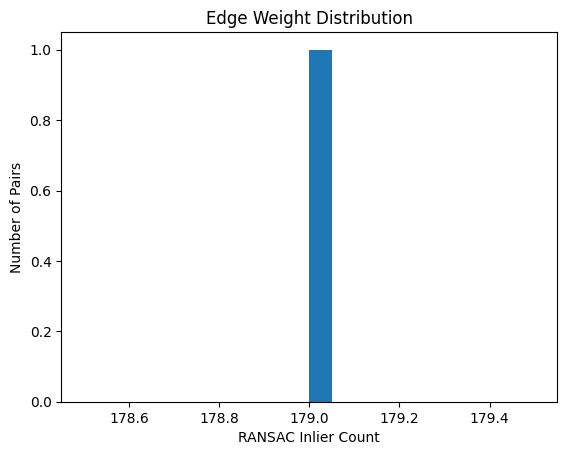

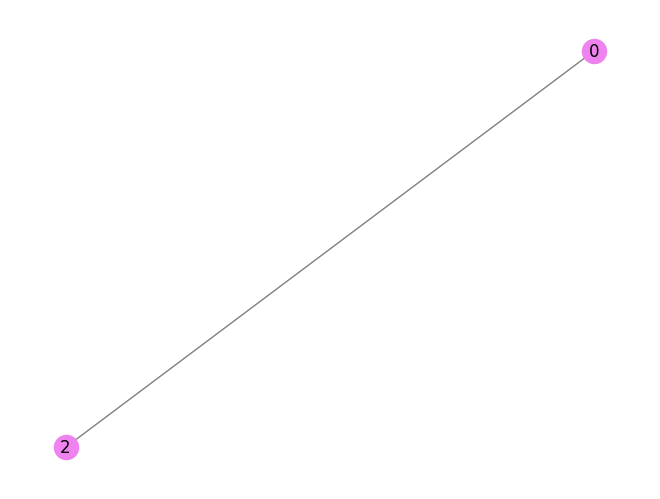

In [67]:
# Extracting features and building similarity graph for global map

features = extract_features(regional_images)
graph = build_similarity_graph(features, regional_images, min_inliers=1)

display_graphs(graph)
global_communities = [frozenset(range(len(regional_images)))] # Treat all regional maps as one community

In [68]:
# Global Map Stitching

stitching_order, bfs_trees, reference_nodes = compute_stitching_order(graph, global_communities)
H_cumulative = compute_homographies(graph, bfs_trees, reference_nodes, global_communities)
global_image = stitch_images(bfs_trees, regional_images, H_cumulative, global_communities)

Group 0: nodes=[0, 1, 2], reference image=0
  Stitching order: [0, 2]
DiGraph with 2 nodes and 1 edges



### Phase 3: Orthorectification

Detects and corrects perspective distortion in the stitched map:
- Checks for significant black border regions (weighted by distance from centre)
- Finds content boundary via convex hull approximation
- Applies perspective transform to map the warped quadrilateral to a true rectangle
- Validates result and returns original if rectification fails

In [69]:
# Check if image needs orthorectification based on black border

def needs_rectification(image, val = False):
    h, w = image.shape[:2]
    cx, cy = w // 2, h // 2  # Centre coordinates

    y, x = np.indices((h, w)) # Generates two 2D grids (y and x) representing the pixel coordinates
    dist = np.sqrt((x - cx)**2 + (y - cy)**2) # Calculates the Euclidean distance from every pixel to center (cx, cy)
    weights = dist / dist.max() # farther from centre means greater weight

    black_mask = (image == 0).all(axis=2) 
    result = black_mask.astype(np.float32) * weights

    weighted_black = np.sum(result)  # sum of weights where pixels are black
    total_weight = np.sum(weights)   # total possible weight across all pixels (if they weren't multiplied by zero for non-black pixels)
    pixel_ratio = (weighted_black / total_weight) * 100

    if val:
        if pixel_ratio > 30:
            return True
        else:
            return False
    else:
        if pixel_ratio > 15:
            return True
        else:
            return False

In [70]:
# Detect boundary of image to rectify it

def detect_boundary(image):
    mask = (image > 0).any(axis=2).astype(np.uint8)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    largest = max(contours, key=cv2.contourArea)
    hull = cv2.convexHull(largest)
    
    # Dynamically adjust epsilon to force exactly 4 points
    peri = cv2.arcLength(hull, True)
    for epsilon_factor in np.linspace(0.01, 0.1, 100):
        approx = cv2.approxPolyDP(hull, epsilon_factor * peri, True)
        if len(approx) == 4:
            break
            
    # If 4 points aren't found, use a bounding box or take the first 4
    if len(approx) != 4:
        rect = cv2.minAreaRect(hull)
        approx = cv2.boxPoints(rect).astype(int)

    pts = approx.reshape(4, 2)
    
    # Sort points 
    s = pts.sum(axis=1)
    diff = np.diff(pts, axis=1)
    ordered_pts = np.zeros((4, 2), dtype="float32")
    ordered_pts[0] = pts[np.argmin(s)]       # top-left
    ordered_pts[2] = pts[np.argmax(s)]       # bottom-right
    ordered_pts[1] = pts[np.argmin(diff)]    # top-right
    ordered_pts[3] = pts[np.argmax(diff)]    # bottom-left

    side1 = math.dist(ordered_pts[0], ordered_pts[1])
    side2 = math.dist(ordered_pts[1], ordered_pts[2])
    
    h, w = sorted([side1, side2])
    aspect_ratio = h / float(w)

    return [largest, ordered_pts, aspect_ratio]


In [71]:
# Apply Homography to image based on image boundary

def apply_homography(image, rectangle):
    cnt = rectangle[0]
    pts = rectangle[1]

    # Order points
    s = pts.sum(axis=1)
    diff = np.diff(pts, axis=1)

    tl = pts[np.argmin(s)]       # Top-left has smallest sum
    br = pts[np.argmax(s)]       # Bottom-right has largest sum
    tr = pts[np.argmin(diff)]    # Top-right has smallest difference
    bl = pts[np.argmax(diff)]    # Bottom-left has largest difference

    src_pts = np.array([tl, tr, br, bl], dtype="float32")

    # Calculate destination dimensions 
    width_top = np.linalg.norm(tr - tl)
    width_bottom = np.linalg.norm(br - bl)
    max_w = int(max(width_top, width_bottom))

    height_left = np.linalg.norm(bl - tl)
    height_right = np.linalg.norm(br - tr)
    max_h = int(max(height_left, height_right))

    dst_pts = np.array([
        [0, 0],
        [max_w - 1, 0],
        [max_w - 1, max_h - 1],
        [0, max_h - 1]], dtype="float32")

    # Apply transformation
    H = cv2.getPerspectiveTransform(src_pts, dst_pts)
    warped = cv2.warpPerspective(image, H, (max_w, max_h))
    
    return warped

In [72]:
# Calls necessary functions to orthorectify image

def orthorectify(image):
    print(needs_rectification(image)) 
    if not needs_rectification(image):  # black boundary pixel check
        return image
    
    boundary = detect_boundary(image)
    rectified = apply_homography(image, boundary)
    
    if not needs_rectification(rectified, val=True):  # black pixel check again
        return rectified
        
    return image  # return original if all attempts fail

True


True

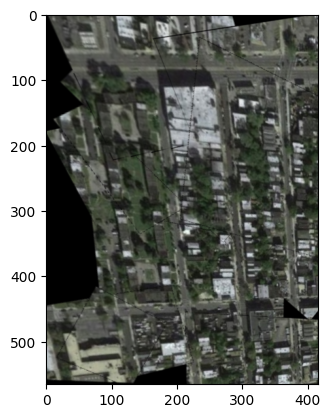

In [73]:
# Display and save top-down image

topdown_image = orthorectify(global_image[0])
plt.imshow(cv2.cvtColor(topdown_image, cv2.COLOR_BGR2RGB))
cv2.imwrite('topdown_image.png', topdown_image)

In [74]:
def safe_hstack(images):
    min_h = min(img.shape[0] for img in images)
    resized = [cv2.resize(img, (int(img.shape[1] * min_h / img.shape[0]), min_h)) for img in images]
    return np.hstack(resized)

In [77]:
base_path = "Datasets/test_s_imgs"
output_path = "results"

os.makedirs(output_path, exist_ok=True)

for folder in os.listdir(base_path):
    folder_path = os.path.join(base_path, folder)

    if not os.path.isdir(folder_path):
        continue
    
    print(f"\nProcessing {folder}...")

    X_train = load_images(folder_path)

    try:
        # ---- Phase 1 ----
        features = extract_features(X_train)

        valid = [(img, feat) for img, feat in zip(X_train, features) if feat[1] is not None]
        if len(valid) < 2:
            print("Not enough valid images after filtering, skipping...")
            continue

        X_train = [v[0] for v in valid]
        features = [v[1] for v in valid]

        graph = build_similarity_graph(features, X_train, min_inliers=20)

        if graph.number_of_edges() == 0:
            print("No edges -> using fallback mosaic")
            final_output = X_train[0] if len(X_train) == 1 else safe_hstack(X_train)
            topdown_image = final_output

        else:
            communities = community.greedy_modularity_communities(graph, weight='weight')

            # ---- Phase 2 (Regional Stitching) ----
            stitching_order, bfs_trees, reference_nodes = compute_stitching_order(graph, communities)
            H_cumulative = compute_homographies(graph, bfs_trees, reference_nodes, communities)
            regional_images = stitch_images(bfs_trees, X_train, H_cumulative, communities, feather_blending=True)

            # Remove empty/invalid regional maps
            filtered = []
            for idx, img in enumerate(regional_images):
                if img is None:
                    continue
                nonzero_ratio = np.count_nonzero(img) / (img.size + 1e-8)
                if nonzero_ratio < 0.01:
                    print(f"Discarding empty regional map {idx}")
                    continue
                filtered.append(img)

            regional_images = filtered

            if len(regional_images) == 0:
                print("All regional maps invalid -> skipping folder")
                continue

            # ---- Global Stitch ----
            global_success = False

            if len(regional_images) > 1:
                features = extract_features(regional_images)
                valid = [(img, feat) for img, feat in zip(regional_images, features) if feat[1] is not None]

                if len(valid) >= 2:
                    regional_images = [v[0] for v in valid]
                    features = [v[1] for v in valid]
                    graph = build_similarity_graph(features, regional_images, min_inliers=10)
                    if graph.number_of_edges() > 0:
                        global_success = True

            if global_success:
                global_communities = [frozenset(range(len(regional_images)))]
                stitching_order, bfs_trees, reference_nodes = compute_stitching_order(graph, global_communities)
                H_cumulative = compute_homographies(graph, bfs_trees, reference_nodes, global_communities)
                global_image = stitch_images(bfs_trees, regional_images, H_cumulative, global_communities)
                final_output = global_image[0]

                nonzero_ratio = np.count_nonzero(final_output) / (final_output.size + 1e-8)
                if nonzero_ratio < 0.01:
                    print("Global map is empty -> falling back")
                    global_success = False
                else:
                    print("Using GLOBAL map")

            if not global_success:
                print("Using fallback")
                if len(regional_images) == 1:
                    final_output = regional_images[0]
                elif len(regional_images) == 2:
                    final_output = safe_hstack(regional_images)
                else:
                    scores = [np.count_nonzero(img) / (img.size + 1e-8) for img in regional_images]
                    final_output = regional_images[np.argmax(scores)]

            # ---- Phase 3 ----
            try:
                topdown_image = orthorectify(final_output)
            except:
                print("Orthorectification failed -> using raw stitched image")
                topdown_image = final_output

        # ---- Save ----
        save_path = os.path.join(output_path, f"{folder}_topdown.png")
        cv2.imwrite(save_path, topdown_image)
        print(f"Saved: {save_path}")

    except Exception as e:
        print(f"Failed on {folder}: {e}")


Processing a_12...
Total matches:  4804
Number of edges (similar pairs): 26
Group 0: nodes=[3, 5, 8, 10, 11], reference image=5
  Stitching order: [5, 10, 11, 8, 3]
DiGraph with 5 nodes and 4 edges

Group 1: nodes=[0, 2, 7], reference image=7
  Stitching order: [7, 0, 2]
DiGraph with 3 nodes and 2 edges

Group 2: nodes=[4, 6, 9], reference image=9
  Stitching order: [9, 4, 6]
DiGraph with 3 nodes and 2 edges

Total matches:  345
Number of edges (similar pairs): 2
Group 0: nodes=[0, 1, 2], reference image=0
  Stitching order: [0, 1, 2]
DiGraph with 3 nodes and 2 edges

Using GLOBAL map
True
Saved: results/a_12_topdown.png

Processing a_15...
Total matches:  0
Number of edges (similar pairs): 0
No edges -> using fallback mosaic
Saved: results/a_15_topdown.png

Processing a_14...
Total matches:  1966
Number of edges (similar pairs): 16
Group 0: nodes=[0, 1, 2, 4, 6], reference image=1
  Stitching order: [1, 4, 2, 6, 0]
DiGraph with 5 nodes and 4 edges

Group 1: nodes=[3, 5, 7], reference